In [1]:
!pip install opencv-python numpy matplotlib

Defaulting to user installation because normal site-packages is not writeable
     -------------------------------------- 44.0/44.0 MB 213.7 kB/s eta 0:00:00
     -------------------------------------- 12.9/12.9 MB 675.8 kB/s eta 0:00:00
     ---------------------------------------- 8.2/8.2 MB 490.3 kB/s eta 0:00:00
     ------------------------------------ 126.4/126.4 kB 322.7 kB/s eta 0:00:00
     ---------------------------------------- 1.6/1.6 MB 350.9 kB/s eta 0:00:00
     ------------------------------------ 221.2/221.2 kB 293.4 kB/s eta 0:00:00
     -------------------------------------- 70.6/70.6 kB 321.3 kB/s eta 0:00:00


  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


Image loaded successfully!
Selected path: C:/Users/acer/OneDrive/Pictures/Camera Roll/input.jpg


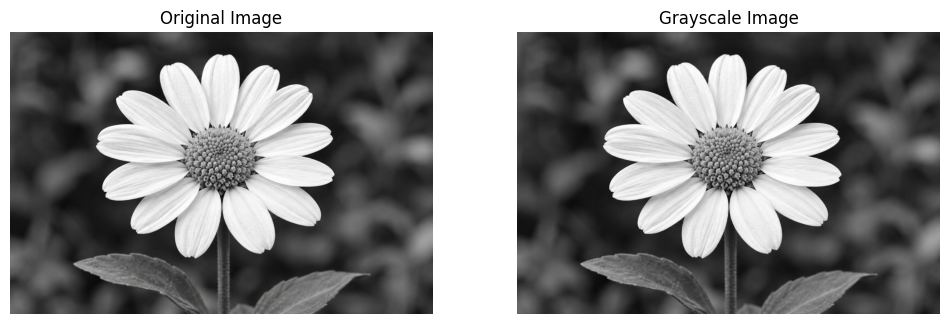

In [12]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import tkinter as tk
from tkinter import filedialog

# Open image selection window
root = tk.Tk()
root.withdraw()

image_path = filedialog.askopenfilename(
    initialdir=r"C:\Users\acer\OneDrive\Pictures\Camera Roll",
    title="Select an Image",
    filetypes=[
        ("Image Files", "*.jpg *.jpeg *.png *.bmp")
    ]
)

# Load selected image
img = cv2.imread(image_path)

if img is None:
    print("Image not loaded. Please select a valid image.")
else:
    print("Image loaded successfully!")
    print("Selected path:", image_path)

    # Convert to grayscale
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Display images
    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.title("Original Image")
    plt.axis("off")

    plt.subplot(1,2,2)
    plt.imshow(gray, cmap="gray")
    plt.title("Grayscale Image")
    plt.axis("off")

    plt.show()

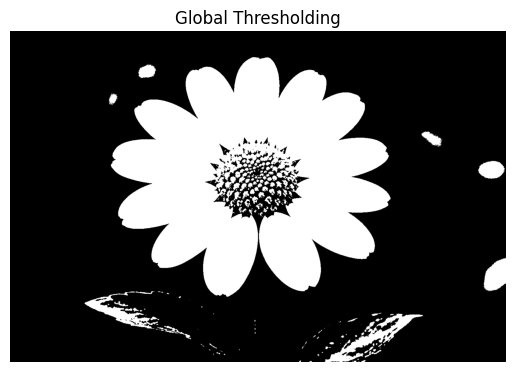

In [10]:
# Apply Global Thresholding
ret, global_thresh = cv2.threshold(
    gray, 127, 255, cv2.THRESH_BINARY
)

plt.imshow(global_thresh, cmap='gray')
plt.title("Global Thresholding")
plt.axis("off")
plt.show()

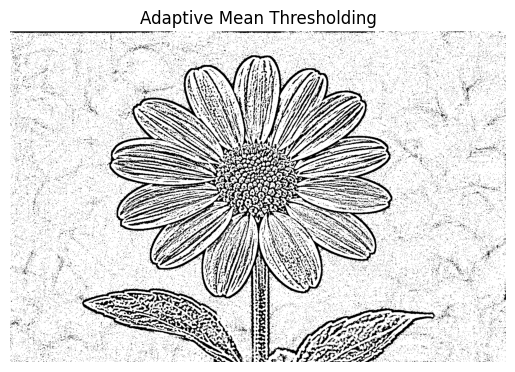

In [13]:
adaptive_mean = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_MEAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.imshow(adaptive_mean, cmap='gray')
plt.title("Adaptive Mean Thresholding")
plt.axis("off")
plt.show()

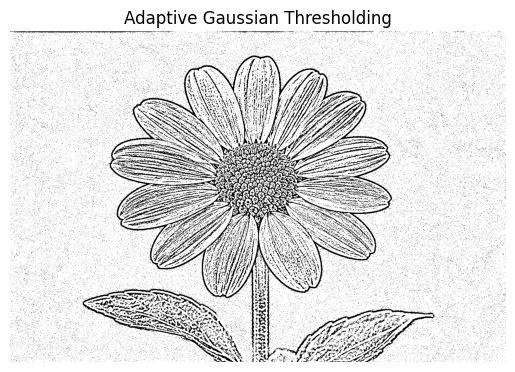

In [14]:
adaptive_gaussian = cv2.adaptiveThreshold(
    gray,
    255,
    cv2.ADAPTIVE_THRESH_GAUSSIAN_C,
    cv2.THRESH_BINARY,
    11,
    2
)

plt.imshow(adaptive_gaussian, cmap='gray')
plt.title("Adaptive Gaussian Thresholding")
plt.axis("off")
plt.show()

Optimal Otsu Threshold Value: 141.0


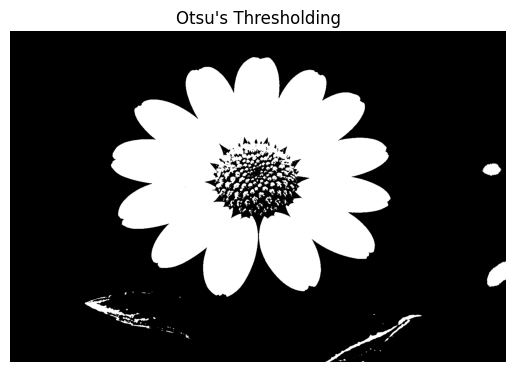

In [15]:
otsu_value, otsu_thresh = cv2.threshold(
    gray,
    0,
    255,
    cv2.THRESH_BINARY + cv2.THRESH_OTSU
)

print("Optimal Otsu Threshold Value:", otsu_value)

plt.imshow(otsu_thresh, cmap='gray')
plt.title("Otsu's Thresholding")
plt.axis("off")
plt.show()